[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bihjane/data-science-and-ai-k-12-teaching-tools/blob/main/intelligent-futures-free-courses/colab-notebooks/02_world_population_linear_vs_exponential.ipynb)

# Choosing a model: how fast did the world grow?
**Level:** beginner · **Time:** 45 minutes · **Models:** linear and exponential

**Question:** The world reached 1 billion people in 1804 and 8 billion in 2022 (United Nations). Which model describes this growth, and what does it predict for 2050?

Steps: load data, graph it, measure growth rates, fit two models, compare their errors, predict and compare with the UN projection.

## How to use this notebook
1. Click **Open in Colab** above, or upload this file at [colab.research.google.com](https://colab.research.google.com) (File > Upload notebook).
2. Run each code cell in order with **Shift + Enter**.
3. Before running a cell, **predict** what it will show. After running it, check your prediction.
4. Try the **Your turn** tasks at the end of each step.

No installs or downloads are needed. Everything runs free in your browser.

## Step 1. Load the data
Year each billion was reached (UN Department of Economic and Social Affairs).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

pop = pd.DataFrame({
    "year":     [1804, 1927, 1960, 1974, 1987, 1999, 2011, 2022],
    "billions": [1, 2, 3, 4, 5, 6, 7, 8],
})
pop["years_to_add_a_billion"] = pop.year.diff()
pop

,year,billions,years_to_add_a_billion
0,1804,1,NaN
1,1927,2,123.0
2,1960,3,33.0
3,1974,4,14.0
4,1987,5,13.0
5,1999,6,12.0
6,2011,7,12.0
7,2022,8,11.0


**Your turn:** What pattern do you see in the years needed to add each billion?

## Step 2. Graph it

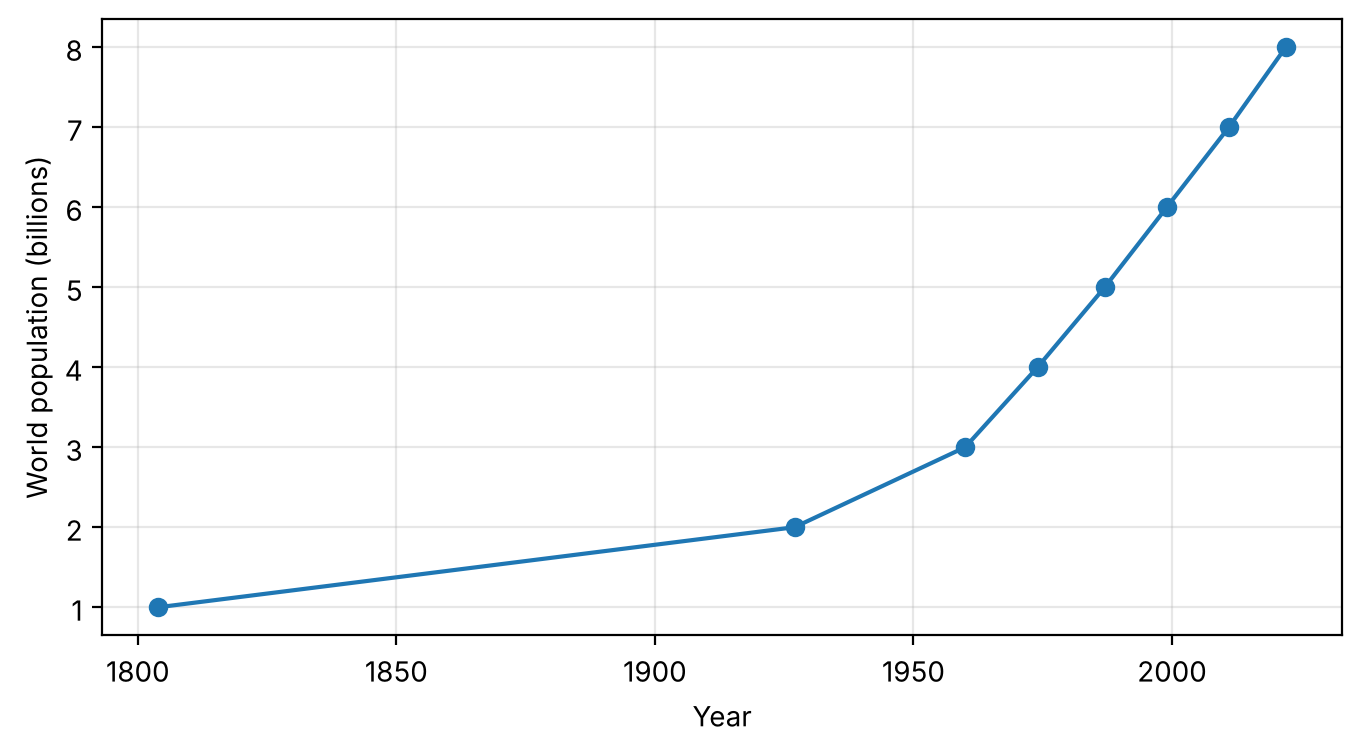

In [2]:
plt.figure(figsize=(8,4))
plt.plot(pop.year, pop.billions, "o-")
plt.xlabel("Year"); plt.ylabel("World population (billions)")
plt.grid(alpha=0.3); plt.show()

## Step 3. Measure the growth rate
An **exponential** model grows by the same percent each year. Let's see if the percent stays the same.

In [3]:
rates = []
for i in range(1, len(pop)):
    p0, p1 = pop.billions[i-1], pop.billions[i]
    years = pop.year[i] - pop.year[i-1]
    rate = (p1 / p0) ** (1 / years) - 1          # yearly growth rate
    rates.append(round(100 * rate, 2))
pop["growth_percent_per_year"] = [None] + rates
pop

,year,billions,years_to_add_a_billion,growth_percent_per_year
0,1804,1,NaN,NaN
1,1927,2,123.0,0.57
2,1960,3,33.0,1.24
3,1974,4,14.0,2.08
4,1987,5,13.0,1.73
5,1999,6,12.0,1.53
6,2011,7,12.0,1.29
7,2022,8,11.0,1.22


The rate rises to about 2% a year (1960 to 1974), then falls to about 1.2%. So the growth is **not** a constant percent.

## Step 4. Fit two models to the data since 1960

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

recent = pop[pop.year >= 1960]
X = recent[["year"]]

lin = LinearRegression().fit(X, recent.billions)
expo = LinearRegression().fit(X, np.log(recent.billions))   # exponential = straight line on a log scale

lin_pred = lin.predict(X)
exp_pred = np.exp(expo.predict(X))
print("Linear:      +", round(lin.coef_[0]*1000, 1), "million people per year")
print("Exponential: +", round(100*(np.exp(expo.coef_[0])-1), 2), "% per year")
print("Linear error (MAE):     ", round(mean_absolute_error(recent.billions, lin_pred), 3), "billion")
print("Exponential error (MAE):", round(mean_absolute_error(recent.billions, exp_pred), 3), "billion")

Linear:      + 80.7 million people per year
Exponential: + 1.58 % per year
Linear error (MAE):      0.063 billion
Exponential error (MAE): 0.158 billion


## Step 5. Predict 2050 and compare with the UN

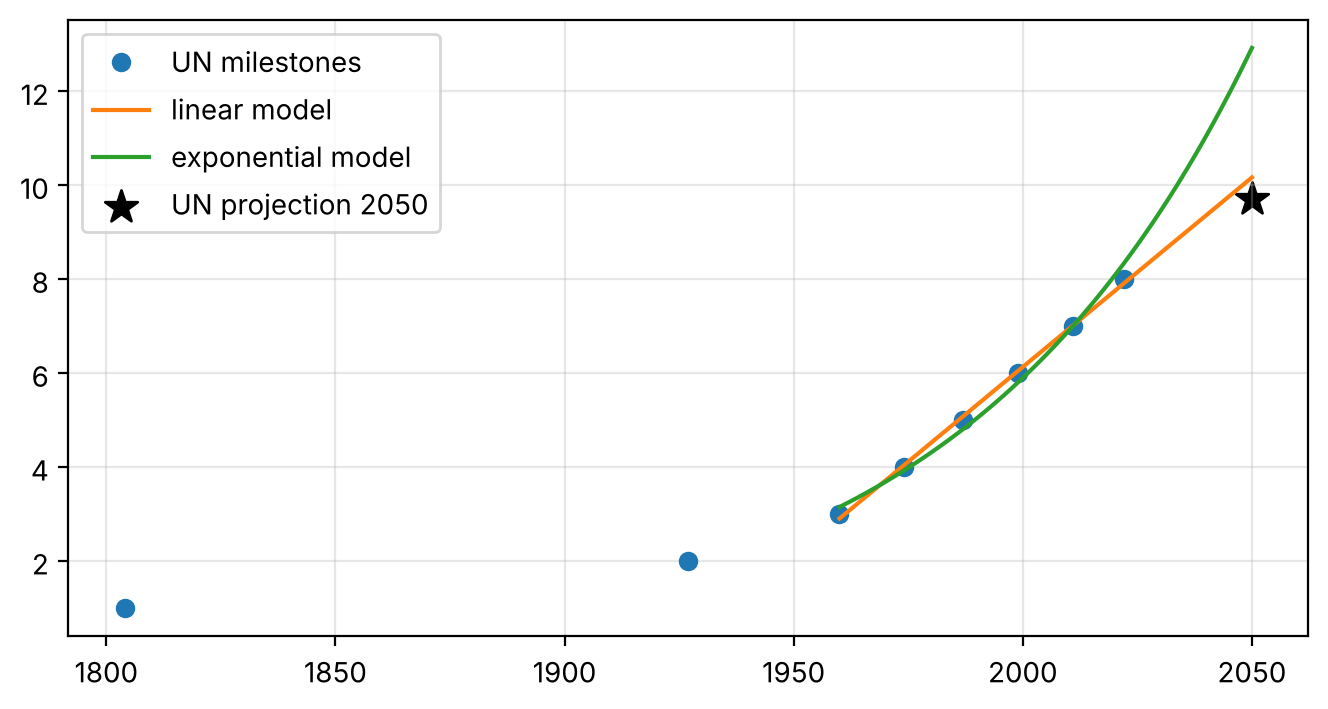

Linear 2050:      10.2 billion
Exponential 2050: 12.9 billion
UN projection:    about 9.7 billion


In [5]:
future = pd.DataFrame({"year": np.arange(1960, 2051)})
plt.figure(figsize=(8,4))
plt.plot(pop.year, pop.billions, "o", label="UN milestones")
plt.plot(future.year, lin.predict(future), label="linear model")
plt.plot(future.year, np.exp(expo.predict(future)), label="exponential model")
plt.scatter([2050], [9.7], color="black", marker="*", s=150, label="UN projection 2050")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print("Linear 2050:     ", round(lin.predict(pd.DataFrame({"year":[2050]}))[0], 1), "billion")
print("Exponential 2050:", round(np.exp(expo.predict(pd.DataFrame({"year":[2050]})))[0], 1), "billion")
print("UN projection:    about 9.7 billion")

Both models overshoot the UN projection because growth keeps slowing. A model that fits the past may not fit the future.

## Your turn: extensions
1. Replace the data with your own country's population from the World Bank (data.worldbank.org) or your national statistics office.
2. Fit a **logistic** curve that levels off: `from scipy.optimize import curve_fit`.
3. Write three sentences: what the data shows, what your model predicts, and one reason the prediction could be wrong.

---
*Intelligent Futures · Dr. Janet Bih Shufor · Free for classroom use with attribution.*